In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

df = pd.read_csv("../data/service_type_large.csv")

In [7]:
#Basic Information
print("📏 Dataset shape (rows, columns):", df.shape)
print("\n🧾 Column names and data types:")
print(df.dtypes)

print("\n🔍 First 5 rows:")
display(df.head())

📏 Dataset shape (rows, columns): (32400, 8)

🧾 Column names and data types:
Yil                    int64
Ay                     int64
Hizmet Turu           object
Muracaat Sayisi        int64
Yasli Nufus Orani    float64
Saglik Enflasyonu    float64
Birim Maliyet        float64
Toplam Harcama       float64
dtype: object

🔍 First 5 rows:


,Yil,Ay,Hizmet Turu,Muracaat Sayisi,Yasli Nufus Orani,Saglik Enflasyonu,Birim Maliyet,Toplam Harcama
0,2015,1,Ayakta,71314,0.17,0.08,549.27,39170640.78
1,2015,1,Ayakta,70935,0.18,0.08,484.39,34360204.65
2,2015,1,Ayakta,103889,0.10,0.08,421.29,43767396.81
3,2015,1,Ayakta,93098,0.20,0.08,404.60,37667450.80
4,2015,1,Ayakta,133168,0.16,0.08,275.93,36745046.24


In [8]:
#Missing Values
print("🧩 Missing value count per column:")
display(df.isnull().sum())

print("\n📊 Missing value percentage:")
display((df.isnull().sum() / len(df) * 100).round(2).astype(str) + '%')

🧩 Missing value count per column:


Yil                  0
Ay                   0
Hizmet Turu          0
Muracaat Sayisi      0
Yasli Nufus Orani    0
Saglik Enflasyonu    0
Birim Maliyet        0
Toplam Harcama       0
dtype: int64


📊 Missing value percentage:


Yil                  0.0%
Ay                   0.0%
Hizmet Turu          0.0%
Muracaat Sayisi      0.0%
Yasli Nufus Orani    0.0%
Saglik Enflasyonu    0.0%
Birim Maliyet        0.0%
Toplam Harcama       0.0%
dtype: object

In [9]:
#Descriptive Statistics for Numerical Columns
print("📊 Descriptive statistics:")
display(df.describe().T)

📊 Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Yil,32400.0,2.019000e+03,2.582029e+00,2015.00,2.017000e+03,2.019000e+03,2.021000e+03,2.023000e+03
Ay,32400.0,6.500000e+00,3.452106e+00,1.00,3.750000e+00,6.500000e+00,9.250000e+00,1.200000e+01
Muracaat Sayisi,32400.0,7.990832e+04,2.171298e+04,379.00,6.474900e+04,7.905450e+04,9.417575e+04,1.914390e+05
Yasli Nufus Orani,32400.0,1.496960e-01,3.008856e-02,0.05,1.300000e-01,1.500000e-01,1.700000e-01,2.700000e-01
Saglik Enflasyonu,32400.0,1.600000e-01,4.944209e-02,0.08,1.200000e-01,1.700000e-01,1.900000e-01,2.400000e-01
Birim Maliyet,32400.0,5.571574e+02,1.933167e+02,87.19,4.006100e+02,5.341150e+02,6.891475e+02,1.414960e+03
Toplam Harcama,32400.0,4.486510e+07,2.104219e+07,248877.93,2.923452e+07,4.114670e+07,5.653339e+07,2.044118e+08


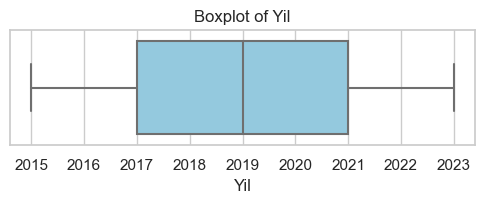

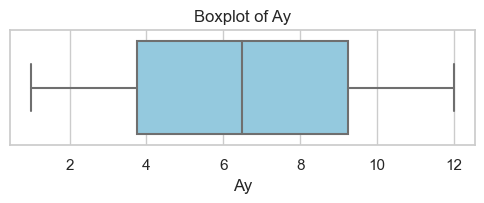

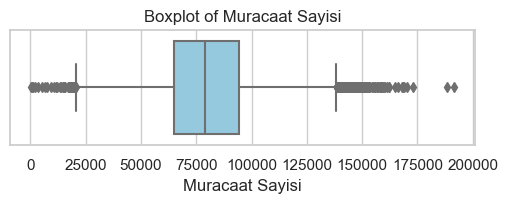

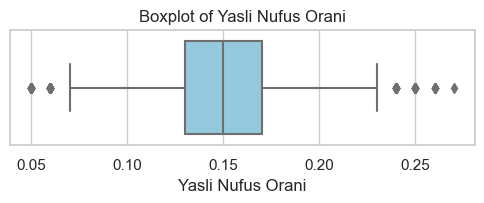

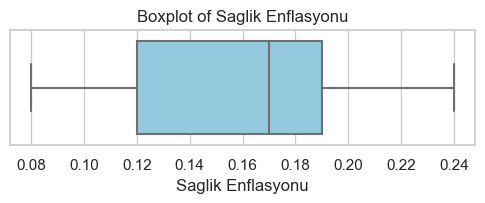

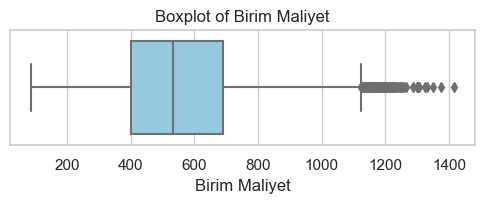

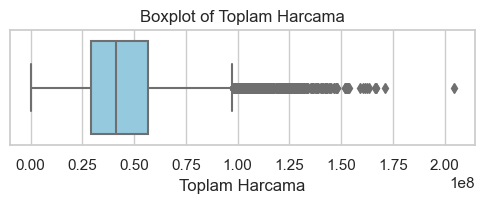

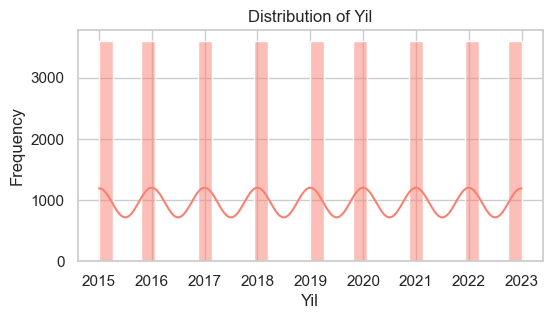

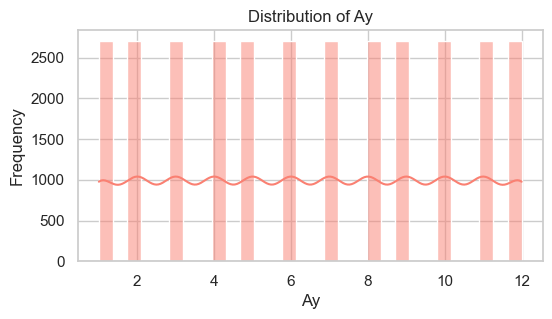

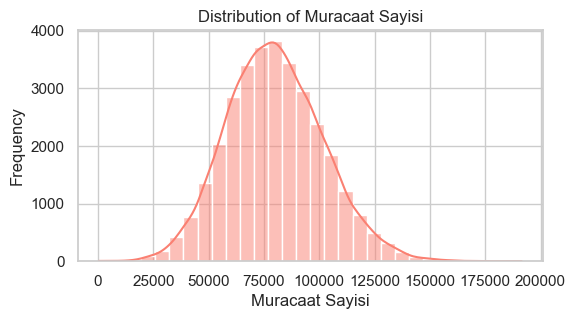

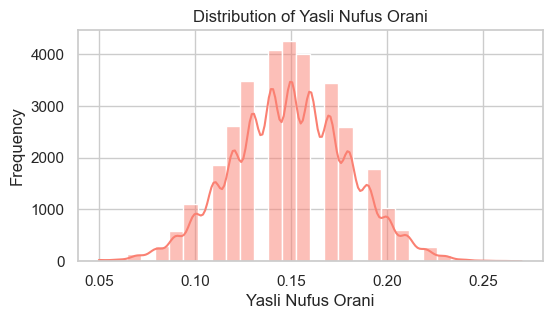

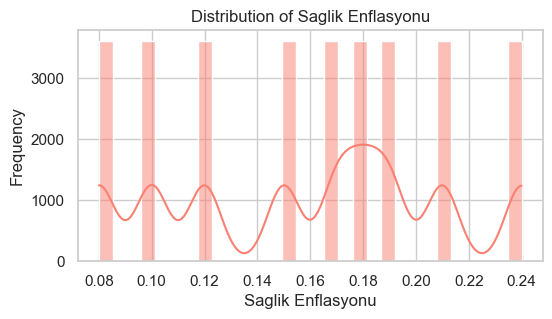

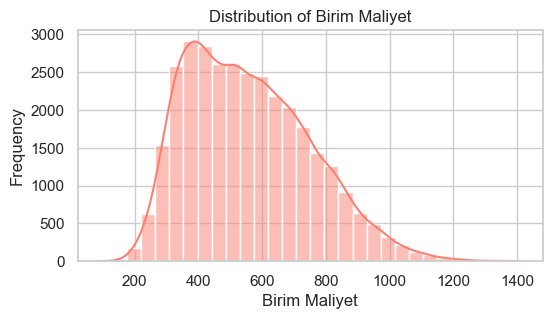

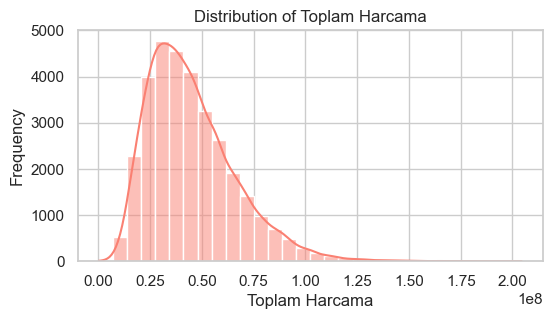

In [12]:
#Outlier Detection: Boxplots and Histograms
# Get numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Boxplots
for col in numeric_cols:
    plt.figure(figsize=(6, 1.5))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Boxplot of {col}")
    plt.show()

# Histograms
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True, bins=30, color="salmon")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

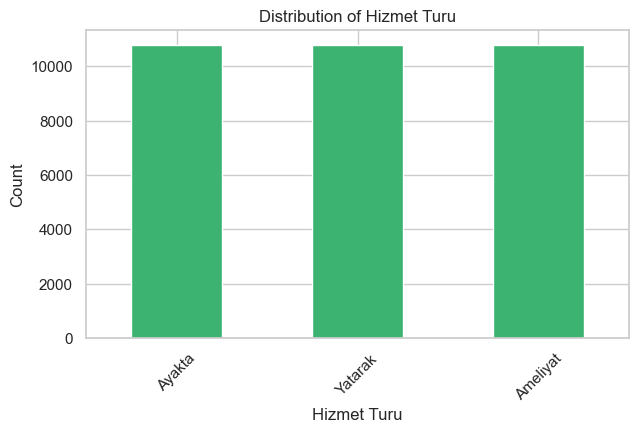

In [13]:
#Categorical Column Distributions
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    df[col].value_counts().plot(kind='bar', color='mediumseagreen')
    plt.title(f"Distribution of {col}")
    plt.ylabel("Count")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.show()

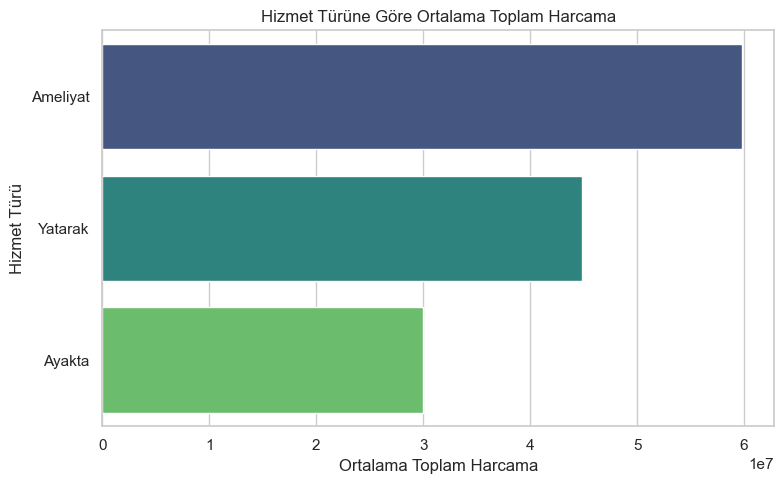

In [24]:
avg_per_service = df.groupby('Hizmet Turu')['Toplam Harcama'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_per_service.values, y=avg_per_service.index, palette="viridis")
plt.title("Hizmet Türüne Göre Ortalama Toplam Harcama")
plt.xlabel("Ortalama Toplam Harcama")
plt.ylabel("Hizmet Türü")
plt.tight_layout()
plt.show()

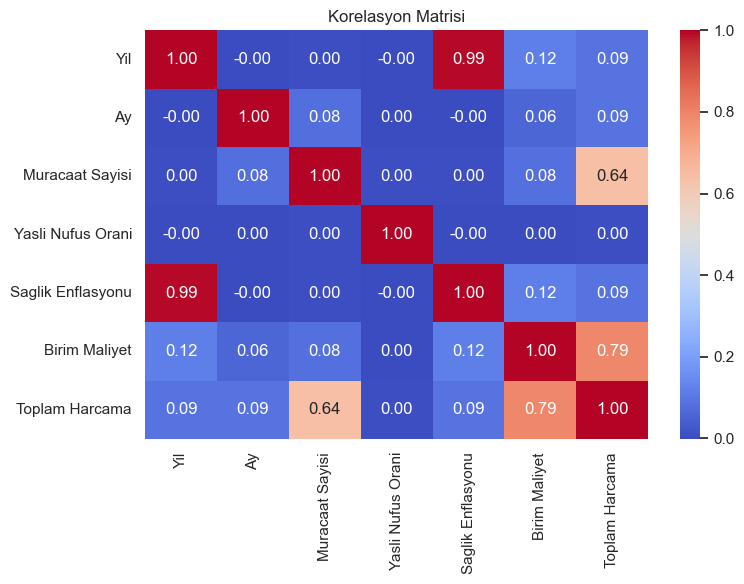

In [23]:
#Correlation Matrix (Heatmap)
#Import numerical columns only
numeric_df = df.select_dtypes(include=[np.number])

#correlation matrix
plt.figure(figsize=(8, 6))
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Korelasyon Matrisi")
plt.tight_layout()
plt.show()